# EDA: dane pasażerów Titanica

Jerzy Śliwa · praca domowa z kursu „Od zera do AI” (moduł 4)

## O Danych

Dane o pasażerach Titanica

Zbiór danych zawiera informacje o pasażerach RMS Titanic, który zatonął 15 kwietnia 1912 roku po zderzeniu z górą
lodową. Dane obejmują takie atrybuty jak klasa podróży, wiek, płeć, liczba rodzeństwa/małżonków na pokładzie,
liczba rodziców/dzieci na pokładzie, cena biletu oraz miejsce zaokrętowania.

Zbiór zawiera także informację o tym, czy pasażer przeżył katastrofę.

Titanic przewoził ponad 2,200 osób, z czego ponad 1,500 zginęło, co czyni tę katastrofę jedną z najbardziej
tragicznych w historii morskiej.

Kolumny:

* **pclass** - Klasa biletu
* **survived** - Czy pasażer przeżył katastrofę
* **name** - Imię i nazwisko pasażera
* **sex** - Płeć pasażera
* **age** - Wiek pasażera
* **sibsp** - Liczba rodzeństwa/małżonków na pokładzie
* **parch** - Liczba rodziców/dzieci na pokładzie
* **ticket** - Numer biletu
* **fare** - Cena biletu
* **cabin** - Numer kabiny
* **embarked** - Port, w którym pasażer wszedł na pokład (C = Cherbourg, Q = Queenstown, S = Southampton)
* **boat** - Numer łodzi ratunkowej
* **body** - Numer ciała (jeśli pasażer nie przeżył i ciało zostało odnalezione)
* **home.dest** - Miejsce docelowe

In [1]:
import pandas as pd

In [2]:
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('26__titanic.csv', sep=",")
df

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1.0,1.0,"Allen, Miss. Elisabeth Walton",female,29.0000,0.0,0.0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1.0,1.0,"Allison, Master. Hudson Trevor",male,0.9167,1.0,2.0,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1.0,0.0,"Allison, Miss. Helen Loraine",female,2.0000,1.0,2.0,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1.0,0.0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1.0,2.0,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1.0,0.0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1.0,2.0,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1305,3.0,0.0,"Zabour, Miss. Thamine",female,NaN,1.0,0.0,2665,14.4542,NaN,C,NaN,NaN,NaN
1306,3.0,0.0,"Zakarian, Mr. Mapriededer",male,26.5000,0.0,0.0,2656,7.2250,NaN,C,NaN,304.0,NaN
1307,3.0,0.0,"Zakarian, Mr. Ortin",male,27.0000,0.0,0.0,2670,7.2250,NaN,C,NaN,NaN,NaN
1308,3.0,0.0,"Zimmerman, Mr. Leo",male,29.0000,0.0,0.0,315082,7.8750,NaN,S,NaN,NaN,NaN


# 1. Ogólny przegląd danych

In [4]:
df.tail()

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
1305,3.0,0.0,"Zabour, Miss. Thamine",female,NaN,1.0,0.0,2665,14.4542,NaN,C,NaN,NaN,NaN
1306,3.0,0.0,"Zakarian, Mr. Mapriededer",male,26.5,0.0,0.0,2656,7.2250,NaN,C,NaN,304.0,NaN
1307,3.0,0.0,"Zakarian, Mr. Ortin",male,27.0,0.0,0.0,2670,7.2250,NaN,C,NaN,NaN,NaN
1308,3.0,0.0,"Zimmerman, Mr. Leo",male,29.0,0.0,0.0,315082,7.8750,NaN,S,NaN,NaN,NaN
1309,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### **Wnioski**:
Ostatni wiersz jest cały pusty – same NaN. Pewnie wkradł się przy zapisie pliku. Do usunięcia.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1310 entries, 0 to 1309
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   float64
 1   survived   1309 non-null   float64
 2   name       1309 non-null   str    
 3   sex        1309 non-null   str    
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   float64
 6   parch      1309 non-null   float64
 7   ticket     1309 non-null   str    
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    str    
 10  embarked   1307 non-null   str    
 11  boat       486 non-null    str    
 12  body       121 non-null    float64
 13  home.dest  745 non-null    str    
dtypes: float64(7), str(7)
memory usage: 143.4 KB


### **Wnioski**:
14 kolumn i 1310 wierszy, ale jeden z nich to ten pusty, więc pasażerów jest 1309. Trochę dziwi, że `pclass`, `survived`, `sibsp` i `parch` są typu float, skoro to liczby całkowite – prawdopodobnie przez ten pusty wiersz. W kilku kolumnach jest sporo braków, wrócę do tego w punkcie 2.

Losuję próbkę z `random_state=1`, żeby przy każdym uruchomieniu była taka sama i wnioski pasowały do wyniku.

In [6]:
df.sample(15, random_state=1)

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
201,1.0,0.0,"McCarthy, Mr. Timothy J",male,54.0,0.0,0.0,17463,51.8625,E46,S,NaN,175.0,"Dorchester, MA"
115,1.0,0.0,"Fortune, Mr. Mark",male,64.0,1.0,4.0,19950,263.0000,C23 C25 C27,S,NaN,NaN,"Winnipeg, MB"
255,1.0,1.0,"Sagesser, Mlle. Emma",female,24.0,0.0,0.0,PC 17477,69.3000,B35,C,9,NaN,NaN
1104,3.0,0.0,"Panula, Mr. Ernesti Arvid",male,16.0,4.0,1.0,3101295,39.6875,NaN,S,NaN,NaN,NaN
195,1.0,1.0,"Maioni, Miss. Roberta",female,16.0,0.0,0.0,110152,86.5000,B79,S,8,NaN,NaN
1032,3.0,0.0,"Morrow, Mr. Thomas Rowan",male,NaN,0.0,0.0,372622,7.7500,NaN,Q,NaN,NaN,NaN
1139,3.0,0.0,"Rekic, Mr. Tido",male,38.0,0.0,0.0,349249,7.8958,NaN,S,NaN,NaN,NaN
288,1.0,1.0,"Swift, Mrs. Frederick Joel (Margaret Welles Ba...",female,48.0,0.0,0.0,17466,25.9292,D17,S,8,NaN,"Brooklyn, NY"
270,1.0,1.0,"Smith, Mrs. Lucien Philip (Mary Eloise Hughes)",female,18.0,1.0,0.0,13695,60.0000,C31,S,6,NaN,"Huntington, WV"
248,1.0,0.0,"Rowe, Mr. Alfred G",male,33.0,0.0,0.0,113790,26.5500,NaN,S,NaN,109.0,London


### **Wnioski**:
Co widać w tej próbce:
- numer kabiny ma 6 z 7 pasażerów 1 klasy, a nikt z 2 i 3 klasy. Ciekawe, czy pozostali nie mieli przypisanych kabin, czy po prostu tego nie zapisano
- wszystkie osoby z `survived = 1` mają numer łodzi, a numer ciała (`body`) mają tylko osoby, które zginęły
- wieku brakuje u 4 osób i wszystkie są z 3 klasy
- część numerów biletów zawiera litery (np. `PC 17477`, `C.A. 2673`), a część to same cyfry

In [7]:
df.describe()

,pclass,survived,age,sibsp,parch,fare,body
count,1309.000000,1309.000000,1046.000000,1309.000000,1309.000000,1308.000000,121.000000
mean,2.294882,0.381971,29.881135,0.498854,0.385027,33.295479,160.809917
std,0.837836,0.486055,14.413500,1.041658,0.865560,51.758668,97.696922
min,1.000000,0.000000,0.166700,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,21.000000,0.000000,0.000000,7.895800,72.000000
50%,3.000000,0.000000,28.000000,0.000000,0.000000,14.454200,155.000000
75%,3.000000,1.000000,39.000000,1.000000,0.000000,31.275000,256.000000
max,3.000000,1.000000,80.000000,8.000000,9.000000,512.329200,328.000000


### **Wnioski**:
Średnia z `survived` to ok. 0,38, czyli przeżyło mniej niż 4 na 10 osób.

Wiek od kilku miesięcy do 80 lat, średnio ok. 30.

Najbardziej zaskoczyła mnie cena biletu – mediana to ok. 14, a najdroższy bilet kosztował ok. 512. Do tego są bilety za 0. Kto płynął Titanikiem za darmo?

In [8]:
df.nunique()

pclass          3
survived        2
name         1307
sex             2
age            98
sibsp           7
parch           8
ticket        929
fare          281
cabin         186
embarked        3
boat           27
body          121
home.dest     369
dtype: int64

### **Wnioski**:
Zgadza się z opisem danych: 3 klasy, 3 porty, 2 płcie. Nazwisk jest 1307, a pasażerów 1309, więc coś się powtarza – sprawdzam niżej. Biletów jest dużo mniej niż osób, czyli na jednym bilecie często płynęło kilka osób.

In [9]:
df[df.duplicated(subset=['name'], keep=False)]

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
725,3.0,1.0,"Connolly, Miss. Kate",female,22.0,0.0,0.0,370373,7.7500,NaN,Q,13,NaN,Ireland
726,3.0,0.0,"Connolly, Miss. Kate",female,30.0,0.0,0.0,330972,7.6292,NaN,Q,NaN,NaN,Ireland
924,3.0,0.0,"Kelly, Mr. James",male,34.5,0.0,0.0,330911,7.8292,NaN,Q,NaN,70.0,NaN
925,3.0,0.0,"Kelly, Mr. James",male,44.0,0.0,0.0,363592,8.0500,NaN,S,NaN,NaN,NaN


### **Wnioski**:
Na pierwszy rzut oka wyglądało to na duplikaty, ale Kate Connolly i James Kelly mają inny wiek i inny numer biletu. To po prostu po dwie osoby o tym samym imieniu i nazwisku, więc niczego nie usuwam.

# 2. Analiza brakujących wartości

In [10]:
df.isnull().sum()

pclass          1
survived        1
name            1
sex             1
age           264
sibsp           1
parch           1
ticket          1
fare            2
cabin        1015
embarked        3
boat          824
body         1189
home.dest     565
dtype: int64

### **Wnioski**:
- połowa kolumn (`pclass`, `survived`, `name`, `sex`, `sibsp`, `parch`, `ticket`) ma tylko 1 brak – to ten pusty wiersz
- `body` jest prawie cała pusta, ale to logiczne, bo numer ma tylko odnalezione ciało
- `cabin` – brak u ok. 3/4 pasażerów
- `boat` – brak raczej oznacza, że ktoś nie był w łodzi
- `age` – 264 braki, czyli po odjęciu pustego wiersza 263 pasażerów (ok. 20%). To już sporo, a wiek jest w tej analizie ważny
- `fare` – 2 braki, `embarked` – 3 braki; po odjęciu pustego wiersza to 1 i 2 pasażerów, łatwo je uzupełnić

In [11]:
df[df['age'].isnull()]['pclass'].value_counts()

pclass
3.0    208
1.0     39
2.0     16
Name: count, dtype: int64

### **Wnioski**:
Wieku brakuje przede wszystkim w 3 klasie (208 z 263). Zastanawiałem się, czy wpisać tam medianę, ale wtedy nagle ok. 200 osób z 3 klasy miałoby po 28 lat, co zafałszowałoby wyniki. Dlatego zostawiam braki i pokazuję je jako osobną grupę.

# 3. Analiza pojedynczych zmiennych

In [12]:
df['survived'].value_counts()

survived
0.0    809
1.0    500
Name: count, dtype: int64

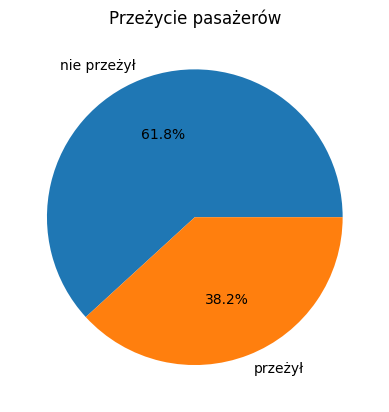

In [13]:
df['survived'].value_counts().plot(kind='pie', labels=['nie przeżył', 'przeżył'], autopct='%1.1f%%')
plt.title('Przeżycie pasażerów')
plt.ylabel('')
plt.show()

### **Wnioski**:
Przeżyło 500 osób, czyli ok. 38% – niewiele ponad jedna trzecia.

In [14]:
df['pclass'].value_counts()

pclass
3.0    709
1.0    323
2.0    277
Name: count, dtype: int64

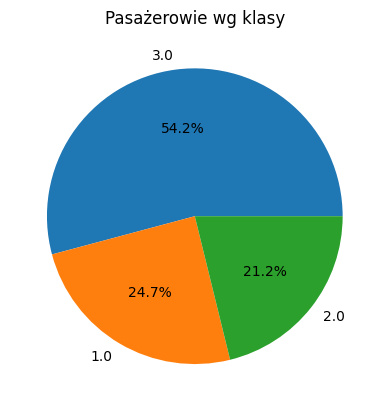

In [15]:
df['pclass'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title('Pasażerowie wg klasy')
plt.ylabel('')
plt.show()

### **Wnioski**:
Ponad połowa pasażerów płynęła 3 klasą (709 z 1309). Myślałem, że najmniej będzie pasażerów 1 klasy, a jednak najmniej liczna była 2 klasa.

In [16]:
df['sex'].value_counts()

sex
male      843
female    466
Name: count, dtype: int64

### **Wnioski**:
Mężczyzn było prawie dwa razy więcej niż kobiet (843 do 466).

In [17]:
df['age'].describe()

count    1046.000000
mean       29.881135
std        14.413500
min         0.166700
25%        21.000000
50%        28.000000
75%        39.000000
max        80.000000
Name: age, dtype: float64

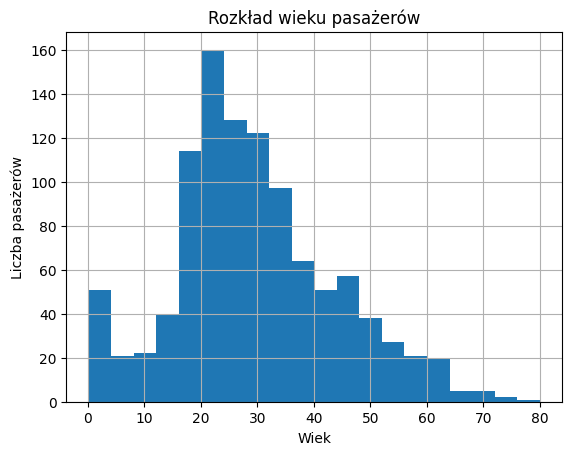

In [18]:
df['age'].hist(bins=20)
plt.title('Rozkład wieku pasażerów')
plt.xlabel('Wiek')
plt.ylabel('Liczba pasażerów')
plt.show()

### **Wnioski**:
Połowa pasażerów miała od 21 do 39 lat (25% i 75% z tabeli), mediana to 28. Na histogramie najwyższe słupki są w okolicy 20-30 lat, widać też wyraźny słupek przy małych dzieciach, a powyżej 60 lat słupki są już bardzo niskie.

In [19]:
df['sibsp'].value_counts()

sibsp
0.0    891
1.0    319
2.0     42
4.0     22
3.0     20
8.0      9
5.0      6
Name: count, dtype: int64

In [20]:
df['parch'].value_counts()

parch
0.0    1002
1.0     170
2.0     113
3.0       8
4.0       6
5.0       6
6.0       2
9.0       2
Name: count, dtype: int64

### **Wnioski**:
891 osób nie miało na pokładzie rodzeństwa ani małżonka, a 1002 nie miały rodziców ani dzieci. Dalej są osoby z jedną bliską osobą (319 i 170) – pewnie w dużej części małżeństwa. Zdarzają się jednak naprawdę duże rodziny – ktoś miał na pokładzie 8 osób rodzeństwa, a ktoś 9 dzieci lub rodziców.

In [21]:
df.groupby('pclass', as_index=False).agg({'fare': ['mean', 'median', 'min', 'max']})

pclass       fare                        
               mean   median  min       max
0    1.0  87.508992  60.0000  0.0  512.3292
1    2.0  21.179196  15.0458  0.0   73.5000
2    3.0  13.302889   8.0500  0.0   69.5500

### **Wnioski**:
Tu bez niespodzianek: 1 klasa najdroższa (mediana 60), 3 klasa najtańsza (mediana ok. 8). Ale bilety za 0 są w każdej klasie – może pracownicy armatora albo zaproszeni goście?

In [22]:
df['embarked'].value_counts()

embarked
S    914
C    270
Q    123
Name: count, dtype: int64

### **Wnioski**:
Zdecydowanie najwięcej osób wsiadło w Southampton, najmniej w Queenstown.

# 4. Transformacja danych / naprawa błędów

Pracuję na kopii `df_t`. Usuwam pusty wiersz i zmieniam typ kolumn na liczby całkowite.

In [23]:
df_t = df.dropna(subset=['name']).copy()

df_t['pclass'] = df_t['pclass'].astype(int)
df_t['survived'] = df_t['survived'].astype(int)
df_t['sibsp'] = df_t['sibsp'].astype(int)
df_t['parch'] = df_t['parch'].astype(int)

df_t.info()

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   str    
 3   sex        1309 non-null   str    
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   str    
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    str    
 10  embarked   1307 non-null   str    
 11  boat       486 non-null    str    
 12  body       121 non-null    float64
 13  home.dest  745 non-null    str    
dtypes: float64(3), int64(4), str(7)
memory usage: 143.3 KB


In [24]:
df_t[df_t['embarked'].isnull()]

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
168,1,1,"Icard, Miss. Amelie",female,38.0,0,0,113572,80.0,B28,NaN,6,NaN,NaN
284,1,1,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,0,0,113572,80.0,B28,NaN,6,NaN,"Cincinatti, OH"


In [25]:
df_t[df_t['fare'].isnull()]

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
1225,3,0,"Storey, Mr. Thomas",male,60.5,0,0,3701,NaN,NaN,S,NaN,261.0,NaN


Brakujący port uzupełniam najczęstszą wartością `S`, a brakującą cenę biletu medianą ceny w 3 klasie (bo pasażer podróżował 3 klasą).

In [26]:
fare_median_3 = df_t[df_t['pclass'] == 3]['fare'].median()

df_t = df_t.fillna({
    'embarked': 'S',
    'fare': fare_median_3,
})

df_t[['embarked', 'fare']].isnull().sum()

embarked    0
fare        0
dtype: int64

Dodaję nowe kolumny: wielkość rodziny na pokładzie i grupę wiekową.

In [27]:
df_t['family_size'] = df_t['sibsp'] + df_t['parch'] + 1
df_t[['name', 'sibsp', 'parch', 'family_size']].head()

,name,sibsp,parch,family_size
0,"Allen, Miss. Elisabeth Walton",0,0,1
1,"Allison, Master. Hudson Trevor",1,2,4
2,"Allison, Miss. Helen Loraine",1,2,4
3,"Allison, Mr. Hudson Joshua Creighton",1,2,4
4,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",1,2,4


In [28]:
def age_category(age):
    if pd.isnull(age):
        return 'brak danych'
    elif age < 12:
        return '0-11'
    elif age < 18:
        return '12-17'
    elif age < 30:
        return '18-29'
    elif age < 45:
        return '30-44'
    elif age < 60:
        return '45-59'
    else:
        return '60+'


df_t['age_group'] = df_t['age'].apply(age_category)
df_t['age_group'].value_counts()

age_group
18-29          415
30-44          301
brak danych    263
45-59          136
0-11            91
12-17           63
60+             40
Name: count, dtype: int64

# 5. Analiza relacji między zmiennymi

Sprawdzam, co sprzyjało przeżyciu katastrofy.

## Płeć

In [29]:
sex_df = df_t.groupby('sex', as_index=False).agg({'survived': ['count', 'sum', 'mean']})
sex_df.columns = ['sex', 'liczba pasażerów', 'przeżyło', 'przeżywalność']
sex_df['przeżywalność %'] = (sex_df['przeżywalność'] * 100).round(1)
sex_df

,sex,liczba pasażerów,przeżyło,przeżywalność,przeżywalność %
0,female,466,339,0.727468,72.7
1,male,843,161,0.190985,19.1


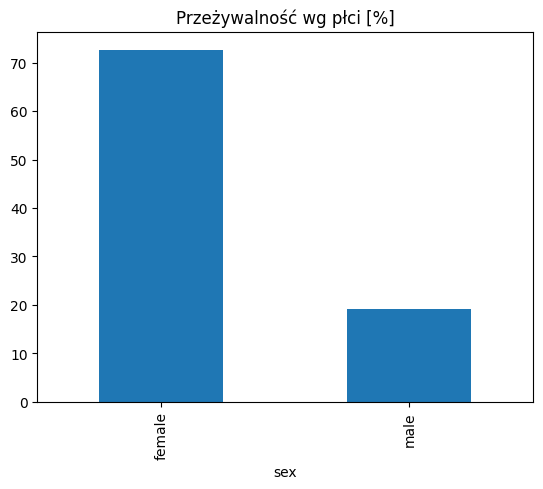

In [30]:
sex_df.plot(kind='bar', x='sex', y='przeżywalność %', legend=False)
plt.title('Przeżywalność wg płci [%]')
plt.show()

### **Wnioski**:
To najmocniejszy wynik w całej analizie. Przeżyło ok. 73% kobiet i tylko ok. 19% mężczyzn. Kobiet było na statku mniej, a mimo to stanowią ponad 2/3 ocalałych. Zasada „najpierw kobiety i dzieci” najwyraźniej działała.

## Klasa

In [31]:
class_df = df_t.groupby('pclass', as_index=False).agg({'survived': ['count', 'sum', 'mean']})
class_df.columns = ['pclass', 'liczba pasażerów', 'przeżyło', 'przeżywalność']
class_df['przeżywalność %'] = (class_df['przeżywalność'] * 100).round(1)
class_df

,pclass,liczba pasażerów,przeżyło,przeżywalność,przeżywalność %
0,1,323,200,0.619195,61.9
1,2,277,119,0.429603,43.0
2,3,709,181,0.255289,25.5


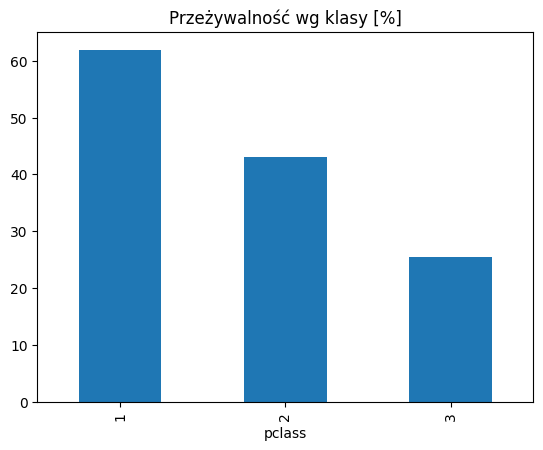

In [32]:
class_df.plot(kind='bar', x='pclass', y='przeżywalność %', legend=False)
plt.title('Przeżywalność wg klasy [%]')
plt.show()

### **Wnioski**:
Im wyższa klasa, tym lepiej: 1 klasa ok. 62%, 2 klasa ok. 43%, 3 klasa ok. 26%. Między 1 a 3 klasą różnica jest ponad dwukrotna.

## Płeć i klasa razem

In [33]:
sex_class_df = df_t.groupby(['pclass', 'sex'])[['survived']].mean().reset_index()
sex_class_df['przeżywalność %'] = (sex_class_df['survived'] * 100).round(1)
sex_class_df['grupa'] = sex_class_df['sex'] + ' ' + sex_class_df['pclass'].astype(str)
sex_class_df

,pclass,sex,survived,przeżywalność %,grupa
0,1,female,0.965278,96.5,female 1
1,1,male,0.340782,34.1,male 1
2,2,female,0.886792,88.7,female 2
3,2,male,0.146199,14.6,male 2
4,3,female,0.490741,49.1,female 3
5,3,male,0.152130,15.2,male 3


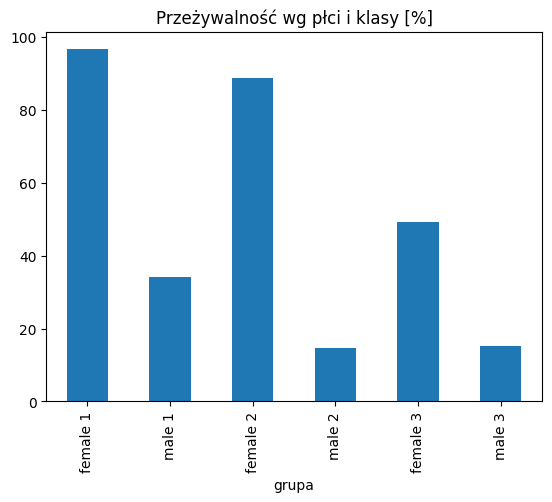

In [34]:
sex_class_df.plot(kind='bar', x='grupa', y='przeżywalność %', legend=False)
plt.title('Przeżywalność wg płci i klasy [%]')
plt.show()

### **Wnioski**:
Tu zrobiło się ciekawie.
- kobiety z 1 i 2 klasy przeżyły prawie wszystkie
- kobiety z 3 klasy – tylko połowa, czyli „najpierw kobiety” nie działało dla wszystkich tak samo
- mężczyźni z 1 klasy mieli ok. 34%, a z 2 i 3 klasy już tylko ok. 15%

Najgorzej było być mężczyzną w 2 lub 3 klasie.

## Wiek

In [35]:
age_df = df_t.groupby('age_group', as_index=False).agg({'survived': ['count', 'mean']})
age_df.columns = ['age_group', 'liczba pasażerów', 'przeżywalność']
age_df['przeżywalność %'] = (age_df['przeżywalność'] * 100).round(1)
age_df

,age_group,liczba pasażerów,przeżywalność,przeżywalność %
0,0-11,91,0.560440,56.0
1,12-17,63,0.476190,47.6
2,18-29,415,0.366265,36.6
3,30-44,301,0.392027,39.2
4,45-59,136,0.470588,47.1
5,60+,40,0.300000,30.0
6,brak danych,263,0.277567,27.8


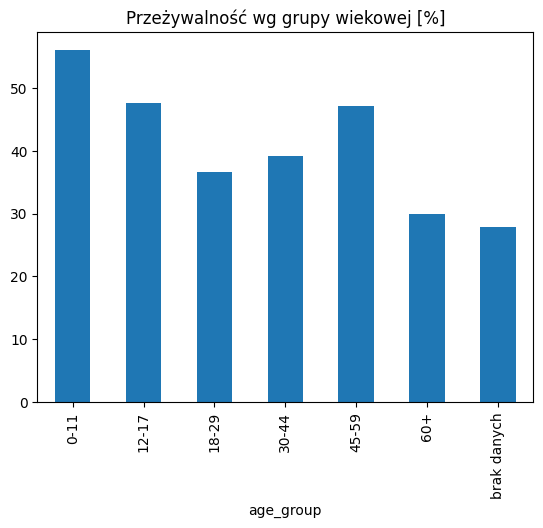

In [36]:
age_df.plot(kind='bar', x='age_group', y='przeżywalność %', legend=False)
plt.title('Przeżywalność wg grupy wiekowej [%]')
plt.show()

### **Wnioski**:
Najwięcej przeżyło dzieci do 11 lat – ok. 56%. W pozostałych grupach wyniki są dość podobne (ok. 37-48%), więc poza dziećmi wiek nie robił dużej różnicy. Słabo wypadają osoby 60+ (30%) i grupa „brak danych” (ok. 28%). W punkcie 2 wyszło, że brak wieku dotyczy głównie 3 klasy, więc niski wynik tej grupy to nie przypadek.

In [37]:
df_t[df_t['age_group'] == '0-11'].groupby('pclass', as_index=False).agg({'survived': ['count', 'mean']})

pclass survived          
            count      mean
0      1        5  0.800000
1      2       22  1.000000
2      3       64  0.390625

### **Wnioski**:
To mnie zaskoczyło. Dzieci z 1 i 2 klasy przeżyły prawie wszystkie (26 z 27), a z 3 klasy tylko ok. 39%. Nawet u dzieci klasa miała znaczenie.

## Cena biletu

In [38]:
df_t.groupby('survived', as_index=False).agg({'fare': ['mean', 'median']})

survived       fare       
                 mean median
0        0  23.334914   10.5
1        1  49.361184   26.0

### **Wnioski**:
Ci, którzy przeżyli, zapłacili za bilet średnio ponad dwa razy więcej. Nie sądzę jednak, żeby chodziło o samą cenę – to raczej znowu klasa, bo droższy bilet to wyższa klasa.

## Port zaokrętowania

In [39]:
df_t.groupby('embarked', as_index=False).agg({'survived': ['count', 'mean']})

embarked survived          
              count      mean
0        C      270  0.555556
1        Q      123  0.357724
2        S      916  0.334061

In [40]:
df_t.groupby(['embarked', 'pclass'])[['name']].count().reset_index()

,embarked,pclass,name
0,C,1,141
1,C,2,28
2,C,3,101
3,Q,1,3
4,Q,2,7
5,Q,3,113
6,S,1,179
7,S,2,242
8,S,3,495


### **Wnioski**:
Na początku wyglądało to tak, jakby wsiadanie w Cherbourgu dawało większe szanse (ok. 56%, a w Southampton ok. 33%). Po rozbiciu na klasy widać jednak, że w Cherbourgu ponad połowa osób wsiadła do 1 klasy (141 z 270), a w Southampton tylko ok. 1/5 (179 z 916). Czyli to najpewniej głównie efekt klasy, a nie samego portu.

## Wielkość rodziny

In [41]:
family_df = df_t.groupby('family_size', as_index=False).agg({'survived': ['count', 'mean']})
family_df.columns = ['family_size', 'liczba pasażerów', 'przeżywalność']
family_df['przeżywalność %'] = (family_df['przeżywalność'] * 100).round(1)
family_df

,family_size,liczba pasażerów,przeżywalność,przeżywalność %
0,1,790,0.302532,30.3
1,2,235,0.536170,53.6
2,3,159,0.566038,56.6
3,4,43,0.697674,69.8
4,5,22,0.272727,27.3
5,6,25,0.200000,20.0
6,7,16,0.250000,25.0
7,8,8,0.000000,0.0
8,11,11,0.000000,0.0


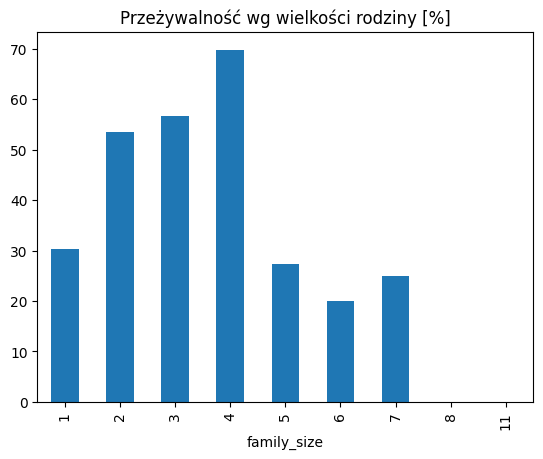

In [42]:
family_df.plot(kind='bar', x='family_size', y='przeżywalność %', legend=False)
plt.title('Przeżywalność wg wielkości rodziny [%]')
plt.show()

### **Wnioski**:
- samotni pasażerowie przeżyli w ok. 30%
- najlepiej wypadły małe rodziny (2-4 osoby)
- rodziny 5-7-osobowe przeżyły tylko w 20-27%, a z rodzin 8- i 11-osobowych nie przeżył nikt

Można się domyślać, że dużej rodzinie trudniej było razem dostać się do łodzi.

## Korelacje

In [43]:
df_t[['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare', 'family_size']].corr()

,survived,pclass,age,sibsp,parch,fare,family_size
survived,1.000000,-0.312469,-0.055513,-0.027825,0.082660,0.244479,0.026876
pclass,-0.312469,1.000000,-0.408106,0.060832,0.018322,-0.558740,0.050027
age,-0.055513,-0.408106,1.000000,-0.243699,-0.150917,0.177285,-0.240230
sibsp,-0.027825,0.060832,-0.243699,1.000000,0.373587,0.160388,0.861952
parch,0.082660,0.018322,-0.150917,0.373587,1.000000,0.221668,0.792296
fare,0.244479,-0.558740,0.177285,0.160388,0.221668,1.000000,0.226653
family_size,0.026876,0.050027,-0.240230,0.861952,0.792296,0.226653,1.000000


### **Wnioski**:
Z przeżyciem najbardziej korelują klasa (ok. -0,31; minus, bo wyższa liczba to gorsza klasa) i cena biletu (ok. 0,24). Klasa i cena są też mocno powiązane ze sobą (ok. -0,56), co pasuje do wcześniejszych obserwacji.

Wiek i wielkość rodziny prawie nie korelują z przeżyciem, ale grupowanie pokazało, że dzieci i małe rodziny miały lepsze szanse. Zależność po prostu nie jest liniowa.

# 6. Analiza wartości odstających

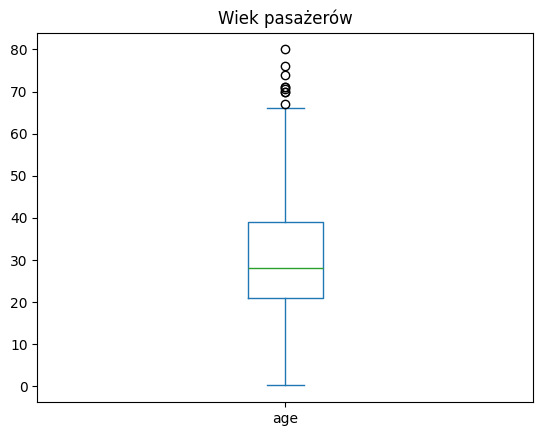

In [44]:
df_t[['age']].plot(kind='box')
plt.title('Wiek pasażerów')
plt.show()

### **Wnioski**:
Nad górnym wąsem jest kilka punktów – to najstarsi pasażerowie (maksimum z `describe` to 80 lat). To realni ludzie, a nie błędy, więc zostawiam.

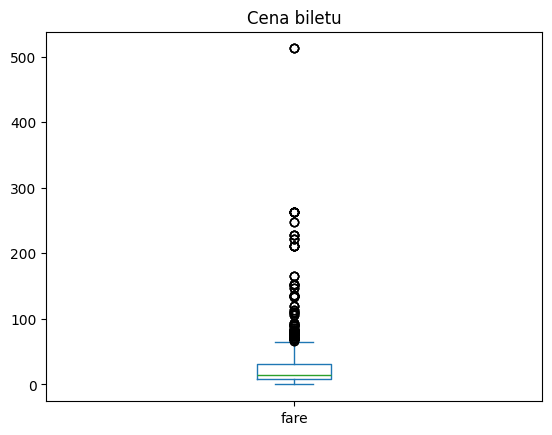

In [45]:
df_t[['fare']].plot(kind='box')
plt.title('Cena biletu')
plt.show()

In [46]:
q1 = df_t['fare'].quantile(0.25)
q3 = df_t['fare'].quantile(0.75)
iqr = q3 - q1
df_t[df_t['fare'] > q3 + 1.5 * iqr]['pclass'].value_counts()

pclass
1    153
3     11
2      7
Name: count, dtype: int64

### **Wnioski**:
Wartości odstających w cenie biletu jest dużo (171) i 153 z nich to 1 klasa. Dlatego przy cenach bardziej ufam medianie niż średniej – w `describe` średnia ceny to ok. 33, a mediana tylko ok. 14, bo drogie bilety mocno zawyżają średnią.

# 7. WNIOSKI KOŃCOWE

Szanse na przeżycie katastrofy Titanica zdecydowanie nie były równe.

1. Przeżyło ok. 38% pasażerów, czyli niewiele ponad co trzecia osoba.
1. Najwięcej znaczyła płeć – przeżyło ok. 73% kobiet i tylko ok. 19% mężczyzn.
1. Zaraz potem klasa. Im wyższa, tym większa szansa, a w 3 klasie przeżyła mniej więcej co czwarta osoba.
1. Dzieci miały lepsze szanse niż dorośli, ale znowu – dzieci z 3 klasy dużo gorsze niż z 1 i 2.
1. Cena biletu i port na początku wyglądały na ważne, ale po sprawdzeniu okazało się, że to w dużej mierze ta sama klasa.
1. Najlepiej wypadły małe rodziny (2-4 osoby). Osoby samotne i duże rodziny miały znacznie mniejsze szanse.

### Największą szansę przeżycia miały:
1. kobiety
1. osoby z 1 klasy (zamożne)
1. dzieci

Najbardziej zaskoczyło mnie, że kobiety z 3 klasy przeżyły tylko w połowie – zasada „najpierw kobiety i dzieci” nie dotyczyła wszystkich w tym samym stopniu.

Trzeba pamiętać, że brakuje wieku dla ok. 20% pasażerów (głównie z 3 klasy), więc wnioski o wieku są przybliżone.